# Homework Reflections 5–8
**Calvin Baker · DX702 — Experimental Design and Causality**

Written responses follow the assignment's limit of about three paragraphs per reflection; code, diagrams, and computed results accompany the responses. Weeks 5 and 7 use explicitly simulated examples. Weeks 6 and 8 use the supplied homework CSV files. Run all cells in order with Python 3; dependencies are NumPy, pandas, SciPy, scikit-learn, Matplotlib, and IPython. Source files are located automatically from the project root or a subfolder.

## Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
from IPython.display import display

pd.set_option('display.precision', 6)
plt.rcParams.update({'figure.figsize': (9, 4.8), 'figure.dpi': 110,
                     'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False})
BLUE, GOLD, DARK = '#2563EB', '#B7791F', '#374151'

def locate_source(filename):
    for folder in (Path.cwd(), *Path.cwd().parents):
        candidate = folder / 'Homework Instructions + Data Files' / filename
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(f'Cannot locate supplied data: {filename}')

def draw_dag(title, nodes, edges, size=(10, 4)):
    fig, ax = plt.subplots(figsize=size)
    ax.set(xlim=(-0.13, 1.13), ylim=(-0.2, 1.2))
    ax.axis('off')
    boxes = {}
    for label, position in nodes.items():
        boxes[label] = ax.text(*position, label, ha='center', va='center', color=DARK,
                bbox={'boxstyle': 'round,pad=.5', 'facecolor': '#EFF6FF',
                      'edgecolor': BLUE})
    fig.canvas.draw()
    for start, end, sign in edges:
        p, q = np.array(nodes[start]), np.array(nodes[end])
        arrow = FancyArrowPatch(p, q, arrowstyle='-|>', mutation_scale=17,
                                patchA=boxes[start].get_bbox_patch(),
                                patchB=boxes[end].get_bbox_patch(),
                                shrinkA=7, shrinkB=7, color=DARK, linewidth=1.5)
        ax.add_patch(arrow)
        if sign:
            middle = (p + q) / 2
            ax.text(*middle, sign, ha='center', va='center', fontsize=13,
                    bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 2})
    ax.set_title(title, pad=15)
    fig.tight_layout()
    plt.show()

## Homework Reflection 5 — Causal diagrams
### 1–2. Negative and positive feedback
**Negative feedback:** higher body temperature at time t increases sweating at t+1, which lowers body temperature at t+2. Time-indexing represents the feedback without placing a directed cycle in the graph; “+” and “−” label increasing and decreasing effects. **Positive feedback:** in a hypothetical social platform, more users at t attract more content creators at t+1, whose additional content attracts more users at t+2. Both effects are positive, so an initial increase is reinforced. Each drawing is one time-unrolled segment of a process that could continue.

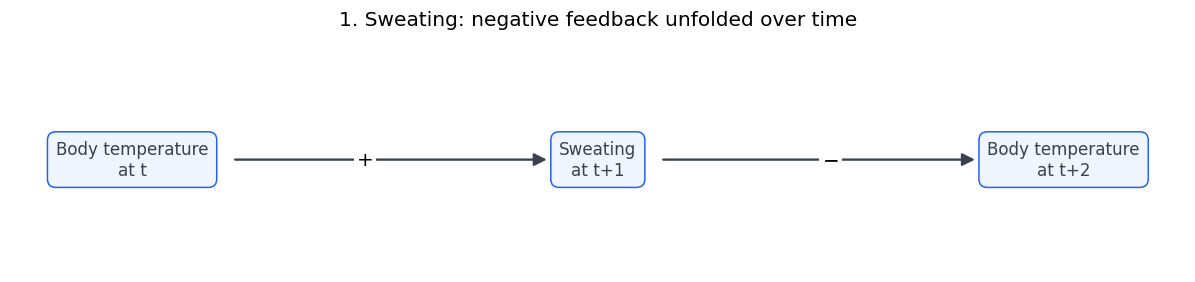

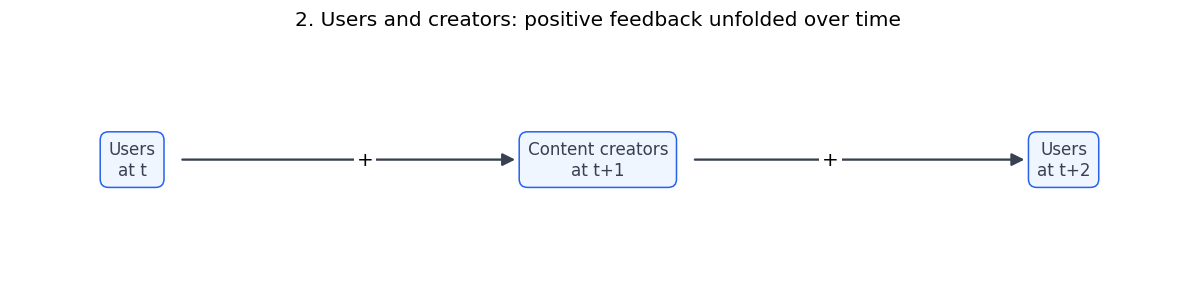

In [2]:
draw_dag('1. Sweating: negative feedback unfolded over time',
         {'Body temperature\nat t': (0, .5), 'Sweating\nat t+1': (.5, .5),
          'Body temperature\nat t+2': (1, .5)},
         [('Body temperature\nat t', 'Sweating\nat t+1', '+'),
          ('Sweating\nat t+1', 'Body temperature\nat t+2', '−')], size=(11, 2.7))
draw_dag('2. Users and creators: positive feedback unfolded over time',
         {'Users\nat t': (0, .5), 'Content creators\nat t+1': (.5, .5),
          'Users\nat t+2': (1, .5)},
         [('Users\nat t', 'Content creators\nat t+1', '+'),
          ('Content creators\nat t+1', 'Users\nat t+2', '+')], size=(11, 2.7))

### 3. Lightning, bears, deer, and flowers
The diagram contains all five specified effects. I simulate 1,000 separate habitats with random storm intensity and Poisson population counts; every variable includes randomness, and the negative/positive coefficients preserve the requested directions in the conditional means. The backdoor paths **Deer ← Storms → Flowers** and **Deer ← Bears ← Storms → Flowers** confound the deer–flower relationship. Storm intensity is a common cause, and bears also lie on the second backdoor path. Conditioning on storms blocks both paths in this invented graph, leaving the direct negative effect of deer on flowers identifiable under the simulation's independent-noise assumptions.

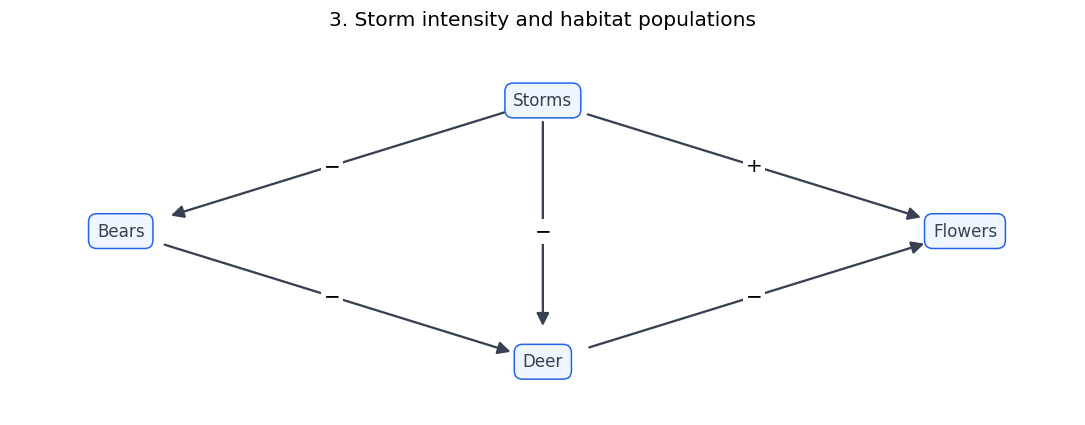

,Storms,Bears,Deer,Flowers
0,2.044710,8,28,138
1,1.527088,12,28,144
2,1.642541,16,17,164
3,0.453514,23,29,103
4,0.748963,15,34,92


Simulated habitats: 1000
Independent draws supply randomness in every equation; counts are nonnegative.


In [3]:
draw_dag('3. Storm intensity and habitat populations',
         {'Storms': (.5, 1), 'Bears': (0, .5), 'Deer': (.5, 0), 'Flowers': (1, .5)},
         [('Storms', 'Bears', '−'), ('Storms', 'Deer', '−'),
          ('Storms', 'Flowers', '+'), ('Bears', 'Deer', '−'),
          ('Deer', 'Flowers', '−')])

rng = np.random.default_rng(508)
n = 1000
storms = rng.gamma(shape=2, scale=.5, size=n)
bears = rng.poisson(np.exp(3 - .35 * storms))
deer = rng.poisson(np.exp(4 - .30 * storms - .025 * bears))
flowers = rng.poisson(np.exp(5 + .20 * storms - .015 * deer))
habitats = pd.DataFrame({'Storms': storms, 'Bears': bears,
                         'Deer': deer, 'Flowers': flowers})
display(habitats.head())
print('Simulated habitats:', len(habitats))
print('Independent draws supply randomness in every equation; counts are nonnegative.')
assert habitats.shape == (1000, 4)
assert np.isfinite(habitats.to_numpy()).all()
assert (habitats[['Bears', 'Deer', 'Flowers']] >= 0).all().all()

### 4. Invented DAG with a confounder and collider
In an invented tutoring study, baseline motivation Z increases both tutoring hours X and exam score Y, while tutoring also increases exam score. Tutoring hours are the treatment and exam score is the outcome. After the exam, tutoring participation and exam score both affect whether a student completes a follow-up survey C, making **X → C ← Y** a collider. Motivation is the confounder on **X ← Z → Y**. To estimate tutoring's total effect, I would adjust for baseline motivation and avoid restricting the sample to survey respondents or controlling for C, which can induce selection bias. Every arrow points forward in the order Z, X, Y, C, so the graph is acyclic.

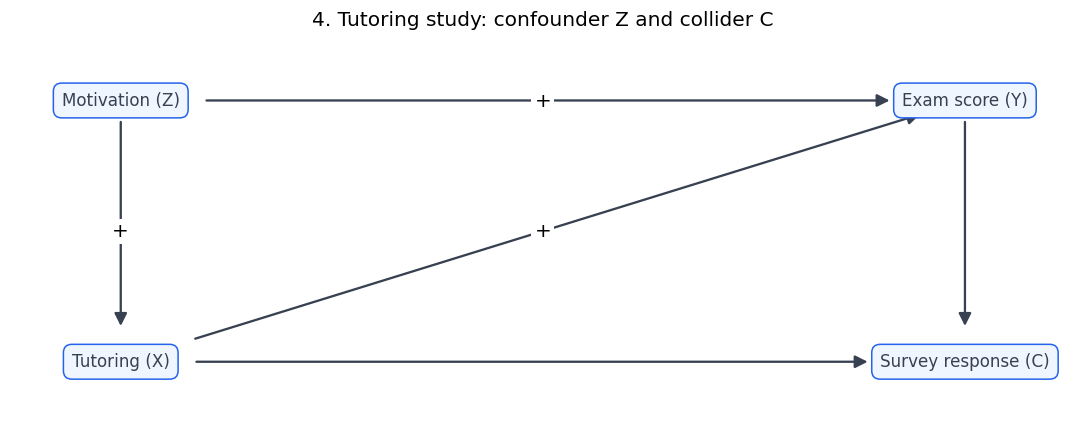

In [4]:
draw_dag('4. Tutoring study: confounder Z and collider C',
         {'Motivation (Z)': (0, 1), 'Tutoring (X)': (0, 0),
          'Exam score (Y)': (1, 1), 'Survey response (C)': (1, 0)},
         [('Motivation (Z)', 'Tutoring (X)', '+'),
          ('Motivation (Z)', 'Exam score (Y)', '+'),
          ('Tutoring (X)', 'Exam score (Y)', '+'),
          ('Tutoring (X)', 'Survey response (C)', ''),
          ('Exam score (Y)', 'Survey response (C)', '')])

## Homework Reflection 6 — Treatment effects

### 1. What is a potential problem with comparing each untreated item to its counterfactual and taking the maximum difference?

Taking the maximum can select a large random error as well as a large true effect. If each estimated effect contains noise, searching many observations favors those whose errors happen to be positive, making the selected maximum prone to upward selection bias (the winner’s curse). A noisy outcome or poor counterfactual match can therefore determine the entire estimate, and the chosen observation may change in a new sample. The maximum is still the quiz’s requested statistic, but its value alone does not establish the largest true treatment effect.

### 2. Propose a solution and write code that implements it. Explain what the solution will do.

I use the 90th percentile of the untreated matched effects as the suggested upper-tail proxy. The code first calculates treated-counterfactual minus untreated-observed Y for every untreated item, then calls `np.quantile(effects, 0.90, method="linear")`. This summarizes a high point of the distribution without allowing one extreme item to set the result: **1.927962**, compared with the maximum **2.172470**. It reduces sensitivity to an isolated extreme value, but changes the target from a maximum to a percentile; it does not fully remove measurement error, matching bias, or unmeasured confounding. This proxy is for the reflection and does not replace Q4’s answer; “MTE” here follows the prompt’s maximum-effect usage.

In [5]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.neighbors import NearestNeighbors

data = pd.read_csv(locate_source("homework_6.1.csv"))
treated = data.loc[data["X"] == 1].reset_index(drop=True)
untreated = data.loc[data["X"] == 0].reset_index(drop=True)
model = NearestNeighbors(n_neighbors=1).fit(treated[["Z"]])
positions = model.kneighbors(untreated[["Z"]], return_distance=False).ravel()
effects = treated.iloc[positions]["Y"].to_numpy() - untreated["Y"].to_numpy()
print(f"Maximum: {effects.max():.6f}")
print(f"90th percentile: {np.quantile(effects, 0.90, method='linear'):.6f}")

Maximum: 2.172470
90th percentile: 1.927962


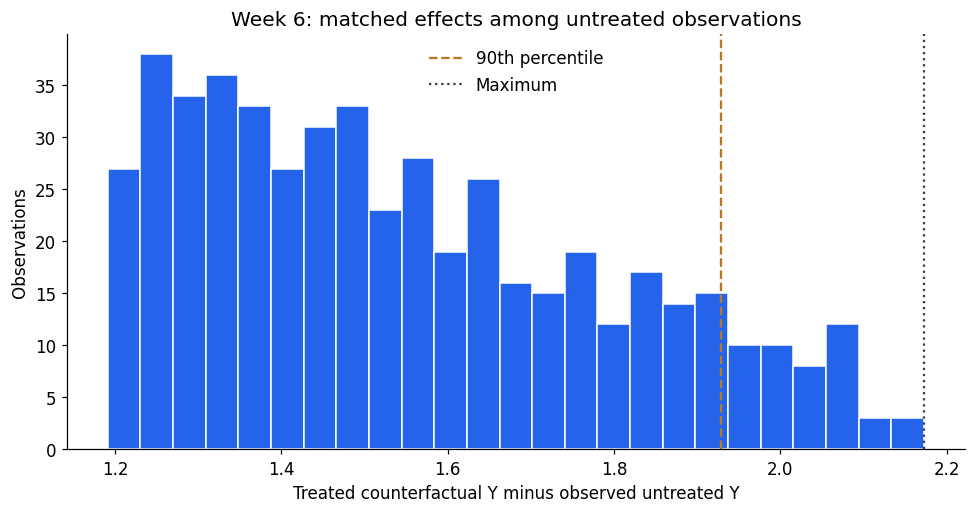

In [6]:
fig, ax = plt.subplots()
ax.hist(effects, bins=25, color=BLUE, edgecolor='white')
ax.axvline(np.quantile(effects, .90), color=GOLD, linestyle='--', label='90th percentile')
ax.axvline(effects.max(), color=DARK, linestyle=':', label='Maximum')
ax.set(title='Week 6: matched effects among untreated observations',
       xlabel='Treated counterfactual Y minus observed untreated Y', ylabel='Observations')
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## Homework Reflection 7 — Regression

### 1. Create a regression with an omitted confounder; determine the direction of bias and explain it.

I generate independent standard-normal Z, treatment noise, and outcome noise, then set X = Z + treatment noise and Y = 2X + 3Z + outcome noise. Z is a confounder because it increases both X and Y. The true causal X coefficient is 2, but leaving Z out overestimates it: the fitted X-only slope is **3.463721**, compared with **1.974390** when Z is included. In the population, the omitted-variable bias is 3 × Cov(X,Z)/Var(X) = 3/2, so the X-only slope is 3.5. The omitted model attributes some of Z’s positive contribution to X. This is bias in the regression coefficient as an estimate of the causal effect; an observed correlation is not itself the causal coefficient.

### 2. Run a regression with a zero coefficient 1,000 times; report the smallest p-value and explain repeated analysis.

For each of 1,000 independent datasets of 100 observations, I generate independent standard-normal W, X, and outcome noise, set Y = 2X + outcome noise, and regress Y on an intercept, X, and W. W’s true coefficient is exactly zero. With seed 7027, the smallest two-sided W p-value is **0.000153434** (trial **279**), and **46** trials produce p < 0.05. This does not mean W’s coefficient is truly nonzero: under the null, a p-value measures the probability of a test statistic at least as extreme as the observed one, not the probability that the null is true. Selecting the smallest result after repeated testing creates false-positive evidence; with independent tests the probability of at least one p < 0.05 is 1 − 0.95^1000, essentially one. Prespecify the test, report all attempts, and if treating the 1,000 tests as a family use a multiplicity correction: the Bonferroni threshold is 0.05/1000 = **0.00005**, which even this minimum does not meet.

In [7]:
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.linear_model import LinearRegression
from IPython.display import display
import matplotlib.pyplot as plt
BLUE, DARK = "#2563EB", "#374151"

def fit_ols(y, predictors):
    # Add an intercept and calculate conventional, homoskedastic OLS SEs.
    y = np.asarray(y, dtype=float)
    predictors = np.asarray(predictors, dtype=float)
    if predictors.ndim == 1:
        predictors = predictors[:, None]
    design = np.column_stack([np.ones(len(y)), predictors])
    assert np.linalg.matrix_rank(design) == design.shape[1]
    beta = np.linalg.lstsq(design, y, rcond=None)[0]
    residuals = y - design @ beta
    df = len(y) - design.shape[1]
    variance = residuals @ residuals / df
    se = np.sqrt(np.diag(np.linalg.inv(design.T @ design)) * variance)
    pvalues = 2 * stats.t.sf(np.abs(beta / se), df)
    return beta, se, pvalues

,Model,X coefficient
0,True causal coefficient,2.000000
1,X only: confounder omitted,3.463721
2,X and Z: confounder included,1.974390


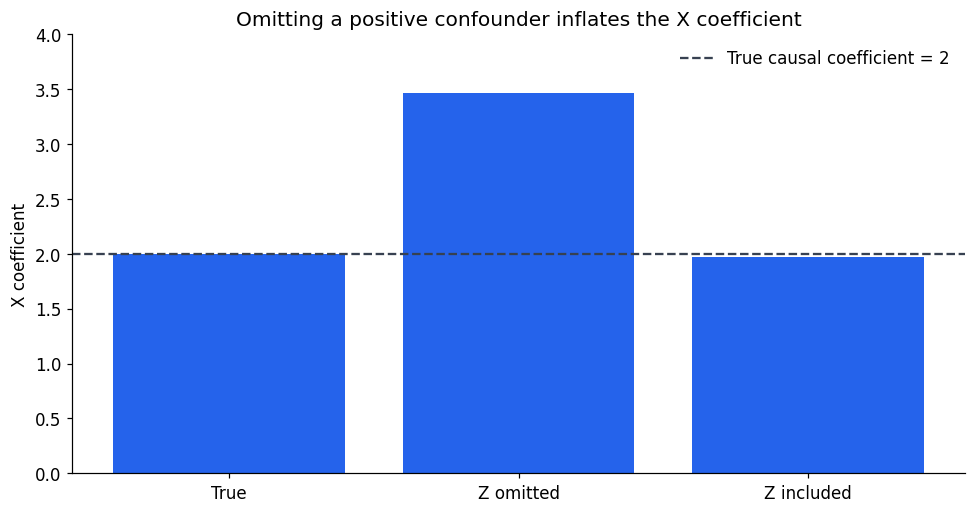

,Measure,Value
0,Smallest W p-value,0.000153
1,Trial with smallest p-value,279.000000
2,W coefficient in that trial,0.424594
3,Trials with p < 0.05,46.000000
4,Bonferroni threshold,0.000050


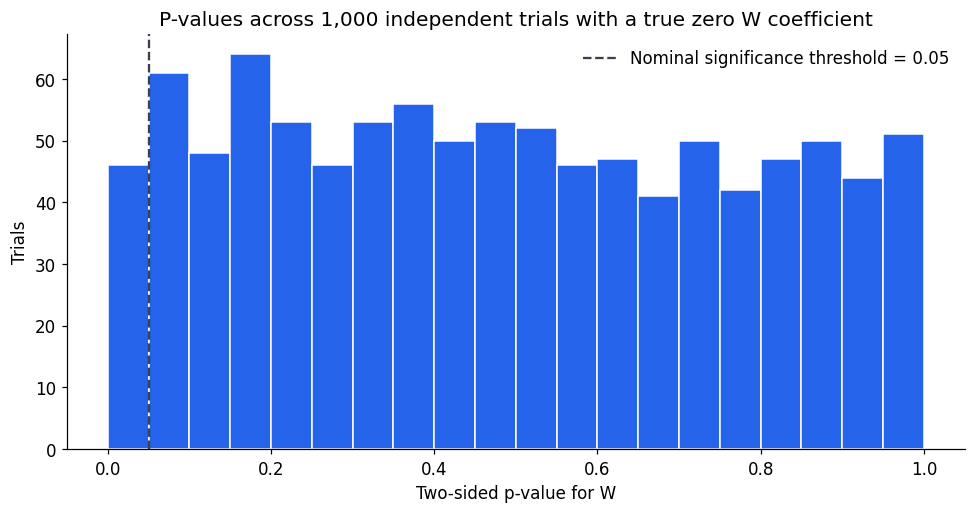

In [8]:
# Reflection 1: positive omitted-variable bias with a known true coefficient.
rng = np.random.default_rng(42)
n = 1000
confounder = rng.normal(size=n)
x = confounder + rng.normal(size=n)
y = 2 * x + 3 * confounder + rng.normal(size=n)
omitted_beta, _, _ = fit_ols(y, x)
adjusted_beta, _, _ = fit_ols(y, np.column_stack([x, confounder]))
reflection_bias = pd.DataFrame({
    'Model': ['True causal coefficient', 'X only: confounder omitted', 'X and Z: confounder included'],
    'X coefficient': [2.0, omitted_beta[1], adjusted_beta[1]],
})
display(reflection_bias)
np.testing.assert_allclose(adjusted_beta[1:], LinearRegression().fit(np.c_[x, confounder], y).coef_)

fig, ax = plt.subplots()
ax.bar(['True', 'Z omitted', 'Z included'], reflection_bias['X coefficient'], color=BLUE)
ax.axhline(2, color=DARK, linestyle='--', label='True causal coefficient = 2')
ax.set(title='Omitting a positive confounder inflates the X coefficient',
       ylabel='X coefficient', ylim=(0, 4))
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

# Reflection 2: every trial has a true W coefficient of zero.
rng = np.random.default_rng(7027)
reflection_trials = []
for trial in range(1000):
    w = rng.normal(size=100)
    x = rng.normal(size=100)
    y = 2 * x + rng.normal(size=100)
    beta, se, pvalues = fit_ols(y, np.column_stack([x, w]))
    reflection_trials.append({'Trial': trial + 1, 'W coefficient': beta[2], 'W p-value': pvalues[2]})
reflection_trials = pd.DataFrame(reflection_trials)
best = reflection_trials.loc[reflection_trials['W p-value'].idxmin()]
false_positives = int((reflection_trials['W p-value'] < 0.05).sum())
bonferroni_threshold = 0.05 / len(reflection_trials)
display(pd.DataFrame({
    'Measure': ['Smallest W p-value', 'Trial with smallest p-value',
                'W coefficient in that trial', 'Trials with p < 0.05', 'Bonferroni threshold'],
    'Value': [best['W p-value'], best['Trial'], best['W coefficient'], false_positives, bonferroni_threshold],
}))
assert best['W p-value'] > bonferroni_threshold

fig, ax = plt.subplots()
ax.hist(reflection_trials['W p-value'], bins=np.linspace(0, 1, 21), color=BLUE, edgecolor='white')
ax.axvline(0.05, color=DARK, linestyle='--', label='Nominal significance threshold = 0.05')
ax.set(title='P-values across 1,000 independent trials with a true zero W coefficient',
       xlabel='Two-sided p-value for W', ylabel='Trials')
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## Homework Reflection 8 — Matching

### Quiz code, implementation challenges, and insights

For inverse probability weighting, I fit an intercept and logistic regression of X on Z using sklearn's default L2 regularization (C = 1), then select the predicted probability of class 1. I keep the original row order, giving first-three propensity scores **[0.840114, 0.584646, 0.711082]** (Q2 **A**). I assign treated weights 1/p and untreated weights 1/(1−p), then subtract the normalized weighted untreated mean of Y from the normalized weighted treated mean. The estimated effect is **2.274341**, so Q1 is **B — 2.3**. Choosing a normalization is an implementation issue: the alternative unnormalized Horvitz–Thompson estimate is **2.239259**, which selects the same option. I check probabilities and weight sizes rather than silently clipping scores or dropping observations; small scores in the treated group or large scores in the untreated group can create influential weights.

For Mahalanobis matching, I stack all Z1 and Z2 values into a 2 × N matrix, compute its sample covariance, and invert that matrix. I explicitly call scipy.spatial.distance.mahalanobis on every treated–untreated pair, choose each treated item's nearest untreated item, and permit repeated use of the same control. Averaging treated Y minus matched untreated Y gives **3.437679**, so Q3 is **D — 3.4**. The main implementation challenges are orienting the covariance matrix correctly, using all observations for covariance as instructed, and preserving positions and original row identifiers after splitting the groups. I independently check every distance with SciPy's vectorized cdist. Although the quiz calls this ATE, averaging only over treated items has an ATT interpretation.

For common support, I first find each treated item's minimum distance to the untreated group, then select the largest of those minima. The weakest-supported treated item is original row **494**, with covariates **(2.696224, 0.538155)**. Its nearest untreated match is original row **418**, with covariates **(1.519995, -1.282208)** and distance **1.383005**, selecting Q4 **D — (1.5, −1.3)**. The key distinction is between the weakest-supported treated observation and the nearest untreated coordinates requested in the choices. Matching always finds a nearest available observation, but that alone does not guarantee a close or credible counterfactual; the distance plot exposes the weak-support tail.

In [9]:
from pathlib import Path
import hashlib
import platform
import importlib.metadata
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from scipy.spatial.distance import mahalanobis, cdist
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option('display.precision', 6)
plt.rcParams.update({'figure.figsize': (9,4.8), 'figure.dpi': 110,
                     'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': .2, 'axes.axisbelow': True})
BLUE, GOLD, DARK = '#2563EB', '#B7791F', '#374151'

def locate_source(filename):
    for folder in (Path.cwd(), *Path.cwd().parents):
        candidate = folder/'Homework Instructions + Data Files'/filename
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(filename)

frames = {}
for filename, required in [('homework_8.1.csv',['X','Y','Z']),
                           ('homework_8.2.csv',['X','Y','Z1','Z2'])]:
    path = locate_source(filename)
    frame = pd.read_csv(path)
    assert set(required).issubset(frame.columns)
    assert np.isfinite(frame[required].to_numpy(dtype=float)).all()
    assert set(frame.X.unique()) == {0,1}
    frames[filename] = frame
    print(filename, 'rows:',len(frame), 'duplicates:',frame.duplicated().sum())
    print('SHA-256:',hashlib.sha256(path.read_bytes()).hexdigest())
data_ipw = frames['homework_8.1.csv']
data_match = frames['homework_8.2.csv']
display(data_ipw.head(3))
display(data_match.head(3))

homework_8.1.csv rows: 1000 duplicates: 0
SHA-256: 7302004ba3e49cfea57398f7931dfca2b5bf92a99d64cce974769c21404adc5e
homework_8.2.csv rows: 1000 duplicates: 0
SHA-256: 799cf7ef12229d3ca183d1c4f635e4a263f1d03340b75ff360c7f3576944fb2b


,X,Y,Z
0,1,4.109218,1.764052
1,0,2.259504,0.400157
2,0,-0.647584,0.978738


,X,Y,Z1,Z2
0,1,4.652085,1.764052,2.320015
1,1,2.590221,0.400157,1.292631
2,1,3.898981,0.978738,0.556423


In [10]:
propensity_model = LogisticRegression(C=1.0, solver='lbfgs', max_iter=1000)
propensity_model.fit(data_ipw[['Z']], data_ipw.X)
class_one = list(propensity_model.classes_).index(1)
propensity = propensity_model.predict_proba(data_ipw[['Z']])[:,class_one]
assert np.all((propensity > 0) & (propensity < 1))
treated_mask = data_ipw.X.to_numpy() == 1
y = data_ipw.Y.to_numpy()
weights = np.where(treated_mask,1/propensity,1/(1-propensity))
weighted_treated = np.average(y[treated_mask],weights=weights[treated_mask])
weighted_untreated = np.average(y[~treated_mask],weights=weights[~treated_mask])
ipw_ate = weighted_treated-weighted_untreated
ht_ate = np.mean(np.where(treated_mask,y/propensity,-y/(1-propensity)))
ipw_summary = pd.DataFrame({'Estimator':['Unweighted outcome difference','Normalized IPW (quiz answer)',
                                         'Unnormalized Horvitz–Thompson'],
    'Effect':[y[treated_mask].mean()-y[~treated_mask].mean(),ipw_ate,ht_ate]})
display(ipw_summary)
display(pd.DataFrame([{'Group':label,'Rows':int(mask.sum()),
    'Min propensity':propensity[mask].min(),'Max propensity':propensity[mask].max(),
    'Max weight':weights[mask].max(),'Effective sample size':weights[mask].sum()**2/(weights[mask]**2).sum()}
    for label,mask in [('Treated',treated_mask),('Untreated',~treated_mask)]]))
print('Q1: B — 2.3; both IPW conventions select B.')

,Estimator,Effect
0,Unweighted outcome difference,3.036626
1,Normalized IPW (quiz answer),2.274341
2,Unnormalized Horvitz–Thompson,2.239259


,Group,Rows,Min propensity,Max propensity,Max weight,Effective sample size
0,Treated,481,0.094932,0.932157,10.533822,385.208797
1,Untreated,519,0.048043,0.921363,12.716721,389.212008


Q1: B — 2.3; both IPW conventions select B.


,X,Y,Z,propensity
0,1,4.109218,1.764052,0.840114
1,0,2.259504,0.400157,0.584646
2,0,-0.647584,0.978738,0.711082


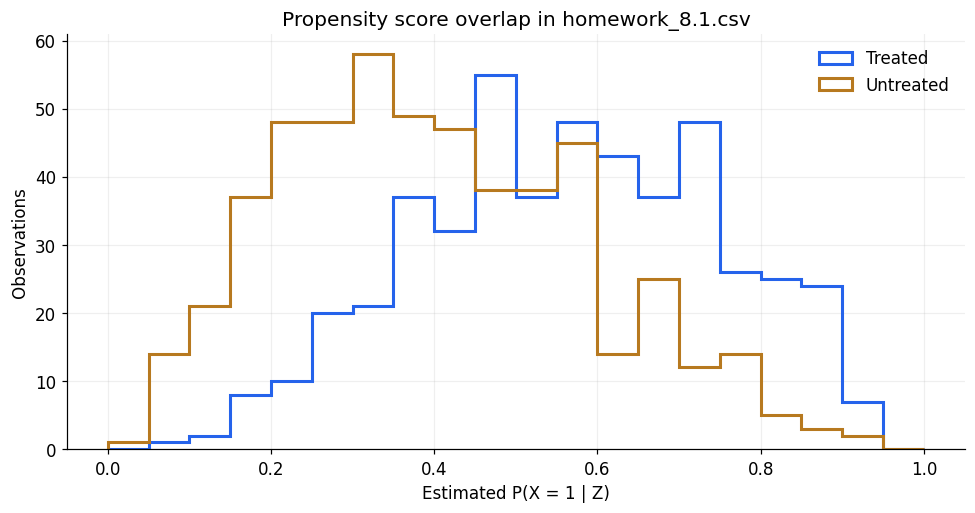

In [11]:
display(data_ipw.head(3).assign(propensity=propensity[:3]))
score_choices = {'A':[.84,.58,.71],'B':[.28,.34,.92],
                 'C':[.08,.65,.38],'D':[.74,.39,.52]}
assert min(score_choices,key=lambda k:np.linalg.norm(propensity[:3]-score_choices[k])) == 'A'
fig, ax = plt.subplots()
for mask,color,label in [(treated_mask,BLUE,'Treated'),(~treated_mask,GOLD,'Untreated')]:
    ax.hist(propensity[mask],bins=np.linspace(0,1,21),histtype='step',linewidth=2,color=color,label=label)
ax.set(title='Propensity score overlap in homework_8.1.csv',xlabel='Estimated P(X = 1 | Z)',ylabel='Observations')
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

In [12]:
covariate_matrix = data_match[['Z1','Z2']].to_numpy().T  # 2 × N, all observations
covariance = np.cov(covariate_matrix, ddof=1)
assert covariance.shape == (2,2)
assert np.linalg.eigvalsh(covariance).min() > 0
inverse_covariance = np.linalg.inv(covariance)
treated = data_match.loc[data_match.X == 1].copy()
untreated = data_match.loc[data_match.X == 0].copy()
zt,zu = treated[['Z1','Z2']].to_numpy(),untreated[['Z1','Z2']].to_numpy()
distances = np.array([[mahalanobis(t,u,inverse_covariance) for u in zu] for t in zt])
nearest_positions = distances.argmin(axis=1)
nearest_distances = distances[np.arange(len(treated)),nearest_positions]
matched = untreated.iloc[nearest_positions]
effects = treated.Y.to_numpy()-matched.Y.to_numpy()
matching_effect = effects.mean()
pairs = pd.DataFrame({'treated_row':treated.index.to_numpy(),
    'untreated_row':matched.index.to_numpy(),'distance':nearest_distances,
    'treated_Y':treated.Y.to_numpy(),'untreated_Y':matched.Y.to_numpy(),
    'effect':effects})
display(pd.DataFrame(covariance,index=['Z1','Z2'],columns=['Z1','Z2']))
display(pairs.head())
print('Treated observations:',len(treated),'Untreated observations:',len(untreated))
print('Unique untreated matches:',np.unique(nearest_positions).size)
print('Mean treated-minus-match effect:',matching_effect)
# A vectorized SciPy implementation independently verifies every distance and match.
np.testing.assert_allclose(distances,cdist(zt,zu,metric='mahalanobis',VI=inverse_covariance))

,Z1,Z2
Z1,0.97521,0.945070
Z2,0.94507,1.853202


,treated_row,untreated_row,distance,treated_Y,untreated_Y,effect
0,0,681,0.648812,4.652085,0.428954,4.223131
1,1,752,0.066003,2.590221,-0.034844,2.625065
2,2,892,0.082207,3.898981,1.164988,2.733993
3,3,922,0.974003,5.857179,1.797450,4.059729
4,4,922,0.687321,3.647489,1.797450,1.850039


Treated observations: 483 Untreated observations: 517
Unique untreated matches: 172
Mean treated-minus-match effect: 3.437678997911326


,X,Y,Z1,Z2
Weakest-supported treated,1.0,6.540236,2.696224,0.538155
Nearest untreated,0.0,5.407995,1.519995,-1.282208


Original zero-based treated row: 494
Original zero-based untreated row: 418
Mahalanobis distance: 1.383004533035377


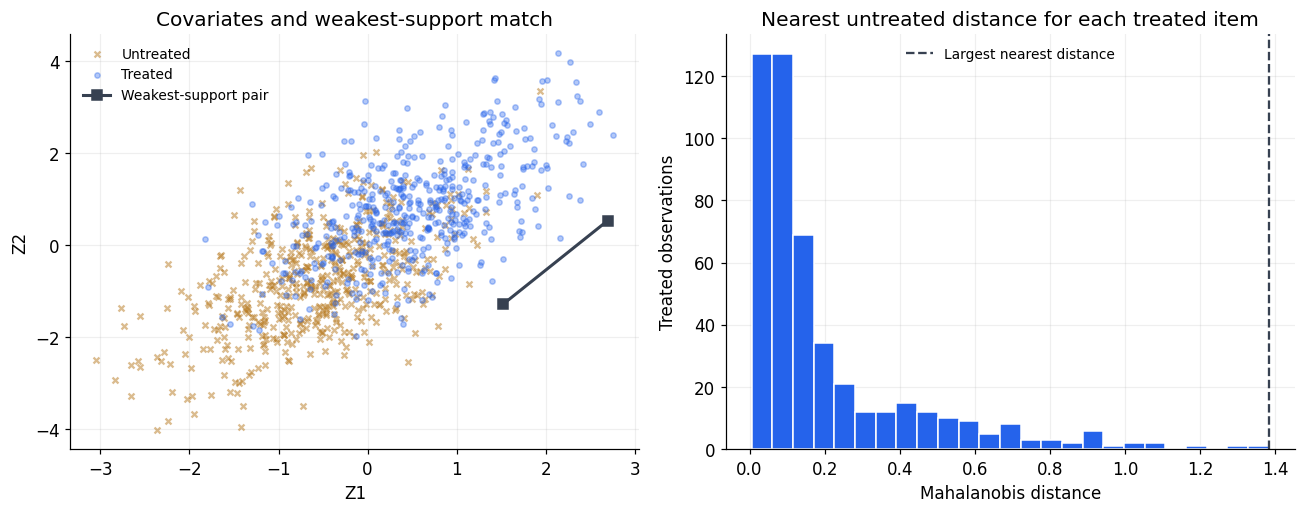

In [13]:
weakest_position = nearest_distances.argmax()
weakest_treated = treated.iloc[weakest_position]
nearest_untreated = untreated.iloc[nearest_positions[weakest_position]]
weakest_pair = pd.DataFrame([weakest_treated,nearest_untreated],index=['Weakest-supported treated','Nearest untreated'])
display(weakest_pair)
print('Original zero-based treated row:',treated.index[weakest_position])
print('Original zero-based untreated row:',untreated.index[nearest_positions[weakest_position]])
print('Mahalanobis distance:',nearest_distances[weakest_position])
q4_coords = nearest_untreated[['Z1','Z2']].to_numpy(dtype=float)
q4_options = {'A':[2.3,1.2],'B':[.2,-.4],'C':[.9,1.4],'D':[1.5,-1.3]}
assert min(q4_options,key=lambda k:np.linalg.norm(q4_coords-q4_options[k])) == 'D'
fig,axes = plt.subplots(1,2,figsize=(12,4.8))
axes[0].scatter(zu[:,0],zu[:,1],s=15,color=GOLD,marker='x',alpha=.5,label='Untreated')
axes[0].scatter(zt[:,0],zt[:,1],s=12,color=BLUE,alpha=.35,label='Treated')
axes[0].plot([weakest_treated.Z1,nearest_untreated.Z1],[weakest_treated.Z2,nearest_untreated.Z2],
             color=DARK,linewidth=2,marker='s',label='Weakest-support pair')
axes[0].set(title='Covariates and weakest-support match',xlabel='Z1',ylabel='Z2')
axes[0].legend(frameon=False,fontsize=9)
axes[1].hist(nearest_distances,bins=25,color=BLUE,edgecolor='white')
axes[1].axvline(nearest_distances.max(),color=DARK,linestyle='--',label='Largest nearest distance')
axes[1].set(title='Nearest untreated distance for each treated item',xlabel='Mahalanobis distance',ylabel='Treated observations')
axes[1].legend(frameon=False,fontsize=9)
fig.tight_layout()
plt.show()